In [9]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
jam = rng.uniform(1, 9, size=60)
nilai = 35 + 5 * jam + rng.normal(loc=0, scale=6, size=60)
df = pd.DataFrame({"jam_belajar": jam,
                   "nilai_ujian": nilai})


In [11]:
df.head()

,jam_belajar,nilai_ujian
0,7.191648,65.763255
1,4.511028,63.364808
2,7.868783,64.246698
3,6.578944,65.885411
4,1.753419,44.743612


In [10]:
df.shape

(60, 2)

In [13]:
df.isna().sum()

,0
jam_belajar,0
nilai_ujian,0


In [14]:
df.describe()

,jam_belajar,nilai_ujian
count,60.000000,60.000000
mean,5.158475,59.549841
std,2.268995,12.131672
min,1.058898,29.930568
25%,3.184446,50.334266
50%,5.121159,60.134906
75%,7.200503,67.910802
max,8.804979,82.542228


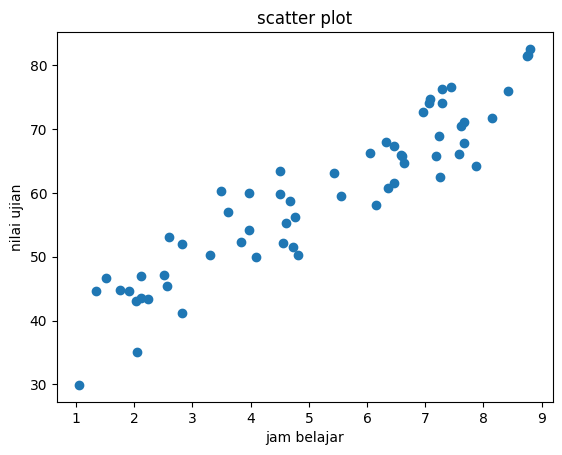

In [16]:
import matplotlib.pyplot as plt

plt.scatter(df['jam_belajar'],
            df['nilai_ujian'])
plt.xlabel("jam belajar")
plt.ylabel("nilai ujian")
plt.title("scatter plot")
plt.show()

In [20]:
from sklearn.model_selection import train_test_split

x = df[["jam_belajar"]]
y = df["nilai_ujian"]
x_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.25, random_state=42)

In [22]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(x_train, y_train)

LinearRegression()

In [27]:
b0 = float(model.intercept_)
b1 = float(model.coef_[0])

print(f"model colab: nilai_prediksi = {b0:.3f} + ({b1:.3f}) x jam_belajar")

model colab: nilai_prediksi = 34.841 + (4.839) x jam_belajar


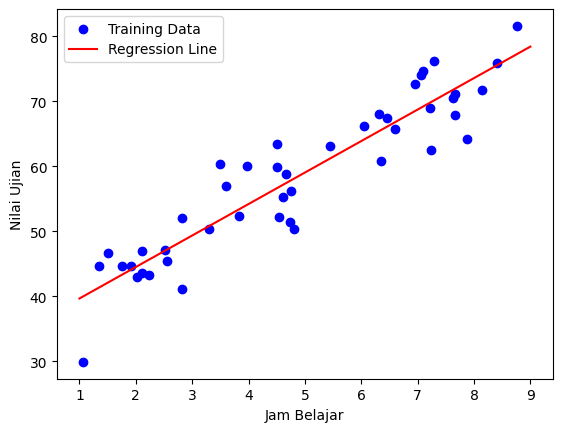

In [31]:
x_grid = pd.DataFrame(
    {"jam_belajar": np.linspace(1, 9, 100)})
y_grid = model.predict(x_grid)

plt.scatter(x_train["jam_belajar"], y_train, color="blue", label="Training Data")
plt.plot(x_grid["jam_belajar"], y_grid, color="red", label="Regression Line")
plt.xlabel("Jam Belajar")
plt.ylabel("Nilai Ujian")
plt.legend()
plt.show()

In [36]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pred_test = model.predict(X_test)
mae = mean_absolute_error(y_test, pred_test)
rmse = np.sqrt(mean_squared_error(y_test, pred_test))
r2 = r2_score(y_test, pred_test)
print(mae)
print(rmse)
print(r2)

4.323764956409487
4.884253621661415
0.8388802621811073
